GPU et version

In [1]:
import torch
print(torch.__version__)
print("GPU disponible :", torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "pas de GPU")

2.14.1+cu130
GPU disponible : True
Tesla T4


importer le dataset

In [3]:
from google.colab import drive
drive.mount('/content/drive')
!unzip -q "/content/drive/MyDrive/projet_vision/kvasir-seg.zip" -d /content/data

Mounted at /content/drive


In [4]:
import os
print(os.listdir("/content/data"))

['Kvasir-SEG']


find the files

In [5]:
import os, glob, random
import numpy as np
import cv2
import matplotlib.pyplot as plt

root = "/content/data"
img_dir = glob.glob(root + "/**/images", recursive=True)[0]
mask_dir = os.path.join(os.path.dirname(img_dir), "masks")

img_paths  = sorted(glob.glob(img_dir  + "/*.jpg"))
mask_paths = sorted(glob.glob(mask_dir + "/*.jpg"))

print(len(img_paths), len(mask_paths))
assert len(img_paths) == len(mask_paths)
assert all(os.path.basename(a) == os.path.basename(b)
           for a, b in zip(img_paths, mask_paths))
print("Images and masks match one to one")

1000 1000
Images and masks match one to one


inspect before processing

In [6]:
sizes = {cv2.imread(p).shape[:2] for p in img_paths[:100]}
print("Different sizes in the first 100 images:", len(sizes))

m = cv2.imread(mask_paths[0], cv2.IMREAD_GRAYSCALE)
print("Mask shape:", m.shape)
print("Unique values in one mask:", len(np.unique(m)))

Different sizes in the first 100 images: 51
Mask shape: (529, 622)
Unique values in one mask: 18


split train /val/ test

In [7]:
from sklearn.model_selection import train_test_split

pairs = list(zip(img_paths, mask_paths))
train_pairs, temp_pairs = train_test_split(pairs, test_size=0.2, random_state=42)
val_pairs, test_pairs   = train_test_split(temp_pairs, test_size=0.5, random_state=42)

print(len(train_pairs), len(val_pairs), len(test_pairs))

800 100 100


transformations

In [8]:
!pip install -q albumentations
import albumentations as A
from albumentations.pytorch import ToTensorV2

IMG_SIZE = 256
MEAN = (0.485, 0.456, 0.406)   # ImageNet statistics, needed later for the pretrained ResNet
STD  = (0.229, 0.224, 0.225)

train_tf = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

val_tf = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

The Dataset and DataLoaders

In [9]:
import torch
from torch.utils.data import Dataset, DataLoader

class PolypDataset(Dataset):
    def __init__(self, pairs, transform):
        self.pairs = pairs
        self.transform = transform

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, i):
        img_path, mask_path = self.pairs[i]
        img  = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)   # BGR -> RGB
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        mask = (mask > 127).astype("float32")                          # binarize: 0 or 1
        out = self.transform(image=img, mask=mask)
        return out["image"], out["mask"].unsqueeze(0)                  # mask -> (1, H, W)

BATCH = 16
train_loader = DataLoader(PolypDataset(train_pairs, train_tf), batch_size=BATCH, shuffle=True,  num_workers=2)
val_loader   = DataLoader(PolypDataset(val_pairs,   val_tf),   batch_size=BATCH, shuffle=False, num_workers=2)
test_loader  = DataLoader(PolypDataset(test_pairs,  val_tf),   batch_size=BATCH, shuffle=False, num_workers=2)

Sanity check

In [10]:
x, y = next(iter(train_loader))
print("Images:", x.shape, x.dtype)
print("Masks :", y.shape, y.dtype, "values:", y.unique())

Images: torch.Size([16, 3, 256, 256]) torch.float32
Masks : torch.Size([16, 1, 256, 256]) torch.float32 values: tensor([0., 1.])


See what the model sees

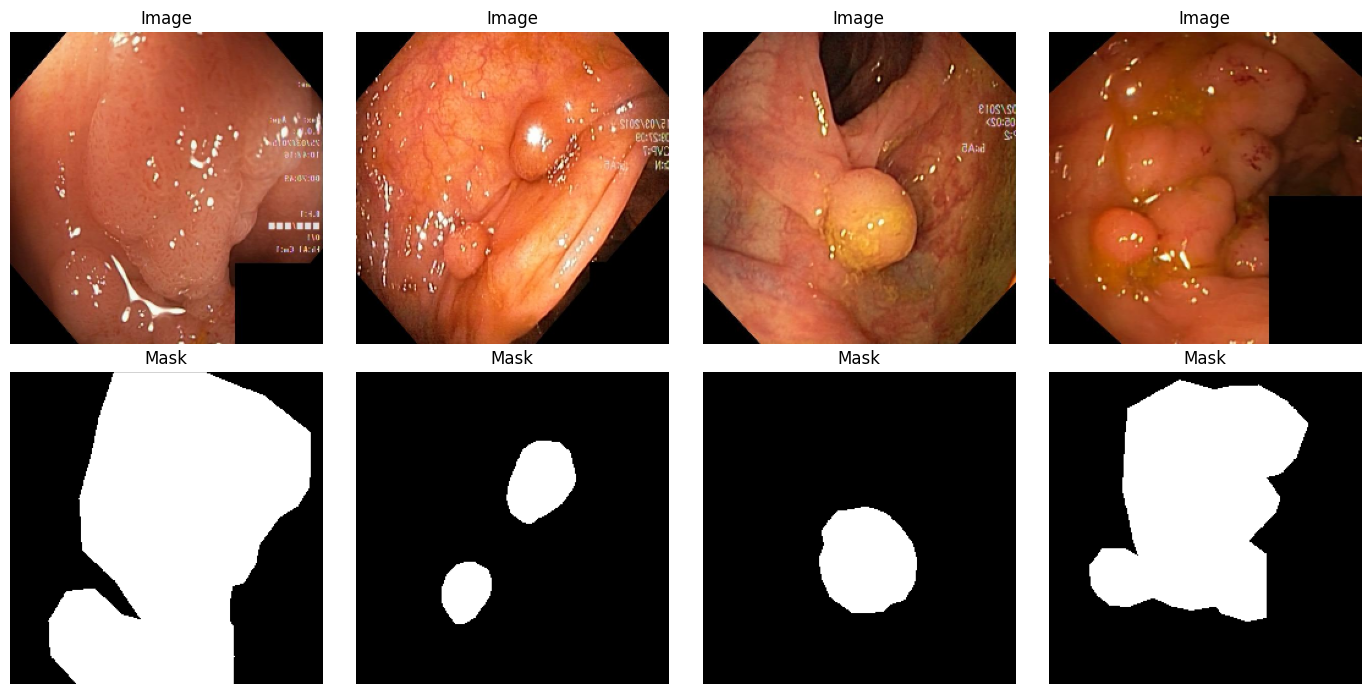

In [11]:
def denorm(t):
    t = t.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)
    return np.clip(t, 0, 1)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i in range(4):
    axes[0, i].imshow(denorm(x[i])); axes[0, i].set_title("Image"); axes[0, i].axis("off")
    axes[1, i].imshow(y[i, 0], cmap="gray"); axes[1, i].set_title("Mask"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()